In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# load dataset
df = pd.read_csv("Mall_Customers.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
# slicing feature anuual income and spending score
X = df.iloc[:, [3, 4]].values

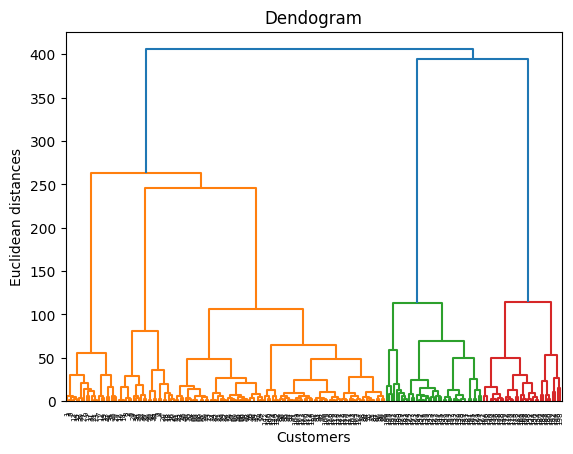

In [ ]:
import scipy.cluster.hierarchy as sch

# build dendogram using ward distance
dendogram = sch.dendrogram(sch.linkage(X, method="ward"))

# plotting
plt.title("Dendogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distances")
plt.show()


In [ ]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
y_hc = hc.fit_predict(X)

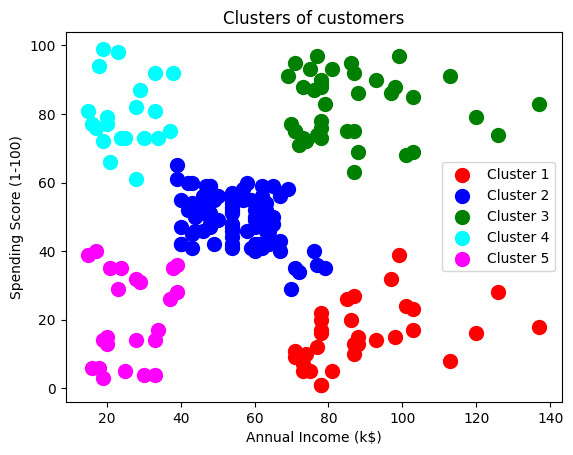

In [ ]:
	# Visualize The Result
	plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
	plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
	plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
	plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s = 100, c = 'cyan', label = 'Cluster 4')
	plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s = 100, c = 'magenta', label = 'Cluster 5')
	plt.title('Clusters of customers')
	plt.xlabel('Annual Income (k$)')
	plt.ylabel('Spending Score (1-100)')
	plt.legend()
	plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

# evaluate the clustering using silhouette score
silhouette_avg = silhouette_score(X, y_hc)
print("The average silhouette_score is :", silhouette_avg)

The average silhouette_score is : 0.5529945955148897
